# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertirse documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | 25–26 de octubre de 2026 |
| **Estudiante** | Eliana Camacho (@ecamachoro-bit) |
| **Corpus A – Documentos (25)** | 8 impresos nítidos y 4 manuscritos históricos peruanos de **archive.org** (John Carter Brown Library, University of Texas, Google Books; dominio público, obras de 1791 a 1905) · 8 fotos y 5 manuscritos **propios** (capturas de la autora, sin datos personales, CC BY 4.0) |
| **Corpus B – Audio (28 clips, 39,3 min)** | Entrevistas y testimonios en español peruano de **Wikimedia Commons** (CC BY 4.0 y CC BY-SA 4.0): El Agustino, UNMSM, Fenmucarinap, Chuyas, Pomabamba y testimonios sobre violencia obstétrica en el Perú |
| **OCR** | PaddleOCR 3.7.0 — PP-OCRv5 mobile det + latin rec, `lang=es` |
| **ASR** | faster-whisper 1.2.1 — Whisper large-v3-turbo (CTranslate2, int8 CPU) + VAD Silero |
| **Diarización** | WeSpeaker ResNet34 (pyannote) + clustering aglomerativo (`voz.diarizar`, Sesión 13) |
| **Seudonimización** | `voz.seudonimizar` (Sesión 13, comparación difusa con rapidfuzz) + revisión manual |

La fuente, licencia y URL de **cada** archivo están en `datos/fuentes.csv`. Los archivos originales no se versionan (`datos/raw/` está en `.gitignore`); se recuperan con `datos_documentos.py` y `datos_audio.py`.

> **Entorno.** Se usó un entorno propio (`uv venv` + `uv pip install`) con los mismos paquetes de los grupos `docai` y `audio` del repositorio del curso. La laptop no tiene GPU (Intel i5-1235U, 7,7 GB de RAM), por eso todo corre en CPU.

In [1]:
import hashlib
import json
import warnings
from datetime import date
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio

warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+png"   # interactivo en Jupyter y PNG visible en GitHub
pd.set_option("display.max_colwidth", 90)

import datos_audio, datos_documentos, procesar_audio, procesar_documentos, voz
import faster_whisper, paddleocr, plotly

print("Fecha de ejecución:", date.today())
print("PaddleOCR", paddleocr.__version__, "| faster-whisper", faster_whisper.__version__, "| plotly", plotly.__version__)

Fecha de ejecución: 2026-10-26
PaddleOCR 3.7.0 | faster-whisper 1.2.1 | plotly 7.1.0


## 1. Corpus A — Documentos

`datos_documentos.armar()` descarga las 12 páginas de archive.org (1500 px de ancho, pausa de 1,5 s, User-Agent descriptivo) y copia las 13 capturas propias desde `datos/raw/documentos/propias/`.

In [2]:
docs = datos_documentos.armar()
print(docs.shape)
docs.groupby(["tipo", "licencia"]).size().rename("n").to_frame()

(25, 8)


n
tipo       licencia                                                        
foto       Captura propia de la autora, sin datos personales (CC BY 4.0)  8
impreso    Dominio público (obra anterior a 1900)                         5
           Dominio público en EE. UU. (publicado antes de 1930)           3
manuscrito Captura propia de la autora, sin datos personales (CC BY 4.0)  5
           Dominio público (obra anterior a 1900)                         4

## 2. OCR con PaddleOCR (Sesión 10)

**Parámetros:** `lang="es"` (reconocedor latino), detector `PP-OCRv5_mobile_det`, sin clasificador de orientación, sin *unwarping* y sin orientación por línea, como en el notebook de la Sesión 10. **Preprocesamiento:** ninguno más allá de reescalar las páginas de archivo a 1500 px de ancho; así el OCR enfrenta las fotos con sombra tal como salen del celular.

Se desactivó oneDNN (`enable_mkldnn=False`) por un error conocido de PaddlePaddle 3.x en Windows. El detector *server* tardaba unos 7 minutos por página en esta CPU, así que se usó el *mobile* (unos 90 s por página).

Por cada documento se guarda en `datos/raw/documentos/ocr/` el **respaldo crudo** (JSON con líneas, confianzas y cajas) y una imagen con las cajas detectadas (`ocr/cajas/`, los recortes).

In [3]:
ocr, MODELO_OCR = procesar_documentos.cargar()
print(MODELO_OCR)
resultados = {r.id: procesar_documentos.leer(Path(datos_documentos.CARPETA.parent.parent.parent, r.archivo), ocr) for r in docs.itertuples()}
docs["texto_ocr"] = docs["id"].map(lambda i: " ".join(resultados[i]["lineas"]))
docs["confianza_media"] = docs["id"].map(lambda i: round(sum(resultados[i]["confianzas"]) / max(1, len(resultados[i]["confianzas"])), 3))
docs["segundos_ocr"] = docs["id"].map(lambda i: resultados[i]["segundos"])
docs["modelo_ocr"] = MODELO_OCR
docs[["id", "tipo", "confianza_media", "segundos_ocr", "texto_ocr"]]

Creating model: ('PP-OCRv5_mobile_det', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\User\.paddlex\official_models\PP-OCRv5_mobile_det`.


Creating model: ('PP-OCRv6_medium_rec', None, None)


Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\User\.paddlex\official_models\PP-OCRv6_medium_rec`.


PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, lang=es, sin orientación ni unwarping, CPU)


,id,tipo,confianza_media,segundos_ocr,texto_ocr
0,doc_001,impreso,0.989,90.2,(5) lo dice el mismo: (14) si esa sabiduria no era mas que redundancia de los inefable...
1,doc_002,impreso,0.839,70.8,5 SLITRA OAG- CAPITULOIII. st eb obio PamDbe w8no RELIJION. t.TA omls Art. 8. La Reli...
2,doc_003,impreso,0.908,78.1,m ART. 35. Los colejios electorales de par- roquia remitirán cerradas y selladas á la ...
3,doc_004,impreso,0.944,182.3,"V. Su Religion es la Católica, Apostólica, Romana, con exclusion del ejercicio de cual..."
4,doc_005,impreso,0.724,154.8,Fol. Núm. 583. hiz ses sb sionsrib ab sibemt ecugol 12 0 bbbelb MERCURIO PERUANO ofbe ...
5,doc_006,impreso,0.927,90.6,"THE LIBRARY THE UNIVERSITY PROVINCIA DE LUYA OF TEXAS CAPITAL LÁMUD. Altura 2,314 metr..."
6,doc_007,impreso,0.970,174.2,"DE LA EDUCACIÓN PUBLICA 15 Siguiendo en este orden de ideas, podremos también colegir..."
7,doc_008,impreso,0.981,100.4,一IX一 denadas de los puntos más importantes que han atravesado. Como anexo al informe d...
8,doc_009,foto,0.986,36.4,Ev Camnaón de neso welter Poca gente me habla hasta oi a alquien Preguntarme ¿De qué t...
9,doc_010,foto,0.988,21.2,se no cazado si he una ohe alcanzad una estre rella 7


## 3. Corpus B — Audio y ASR con `voz.py` (Sesión 13)

Pipeline de `procesar_audio.py`, que usa las funciones de `voz.py`:

1. **VAD** (Silero, dentro de faster-whisper): solo se transcribe donde hay voz. Evita que Whisper *alucine* frases en silencios o ruido.
2. **Transcripción** con Whisper large-v3-turbo (faster-whisper, int8, `beam_size=5`, `language="es"`).
3. **Diarización** en las entrevistas multihablante de El Agustino (`clip_003`, `clip_004`): huella de voz WeSpeaker por segmento + clustering aglomerativo coseno.
4. **Exportación** a CSV (segmentos con tiempos y hablante), SRT y TXT en `datos/raw/audio/salidas/`.

In [4]:
fuentes_audio = datos_audio.bajar()
SALIDAS = procesar_audio.SALIDAS
tr = None
filas = []
for cid in fuentes_audio["id"]:
    if not (SALIDAS / f"{cid}.json").exists():          # solo carga el modelo si falta algún clip
        tr = tr or voz.Transcriptor(procesar_audio.MODELO)
    info = procesar_audio.procesar(cid, tr)
    seg = pd.read_csv(SALIDAS / f"{cid}.csv")
    if info["n_hablantes"] > 1:   # marcas de hablante: H1 -> [HABLANTE_1]
        texto = " ".join(f"[HABLANTE_{h[1:]}] {t}" for h, t in zip(seg["hablante"], seg["texto"].fillna("")))
    else:
        texto = " ".join(seg["texto"].fillna(""))
    filas.append(info | {"texto_asr": texto, "condicion": fuentes_audio.set_index("id").loc[cid, "condicion"]})
audio = pd.DataFrame(filas)
audio["factor_tiempo_real"] = (audio["segundos_proceso"] / audio["duracion_seg"]).round(2)
print(f"{len(audio)} clips · {audio['duracion_seg'].sum() / 60:.1f} min · RTF medio {audio['factor_tiempo_real'].mean():.2f}")
audio[["id", "condicion", "duracion_seg", "n_segmentos", "n_hablantes", "factor_tiempo_real"]]

28 clips · 39.3 min · RTF medio 1.07


,id,condicion,duracion_seg,n_segmentos,n_hablantes,factor_tiempo_real
0,clip_001,entrevista en exteriores,497.7,67,1,0.84
1,clip_002,conferencia de prensa,250.6,37,1,0.69
2,clip_003,"calle, multihablante",136.3,25,2,0.68
3,clip_004,"calle, multihablante",189.0,51,3,0.93
4,clip_005,"marcha, ruido de multitud",95.0,15,1,0.98
5,clip_006,"marcha, ruido de multitud",77.4,15,1,0.78
6,clip_007,"marcha, ruido de multitud",54.3,14,1,1.01
7,clip_008,entrevista en exteriores,98.3,5,1,0.20
8,clip_009,entrevista en exteriores,81.6,17,1,1.22
9,clip_010,entrevista en exteriores,39.2,2,1,0.94


In [5]:
# Diarización: la entrevista de El Agustino con su exportación SRT (seudonimizada antes de mostrarla)
from seudonimos import aplicar
print(aplicar("clip_003", (SALIDAS / "clip_003.srt").read_text(encoding="utf-8")[:700]))

1
00:00:00,340 --> 00:00:07,700
[H1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca del partido de hoy.

2
00:00:08,440 --> 00:00:09,720
[H1] ¿Puede decirme su nombre, por favor?

3
00:00:10,300 --> 00:00:11,380
[H2] [PERSONA_02].

4
00:00:12,180 --> 00:00:17,620
[H1] Mucho gusto, yo soy [PERSONA_03], soy alumno de la Universidad Nacional Mayor de San Marcos

5
00:00:17,620 --> 00:00:21,520
[H1] y le voy a hacer estas preguntas acerca del partido de hoy.

6
00:00:22,540 --> 00:00:26,000
[H1] ¿Qué expectativas tiene acerca de este partido?

7
00:00:26,420 --> 00:00:29,200
[H1] ¿Quién piensa que va a atacar más o defender?

8
00:00:29,200 --> 00:00:33,850
[H2


## 4. Seudonimización

**Criterio:** se reemplazan nombres de **personas privadas** (entrevistados, entrevistadores y personas mencionadas). Se conservan las figuras públicas (futbolistas de la selección, Micaela Bastidas), las instituciones y los lugares, porque no identifican a un particular. La maniobra de *Kristeller* es un término médico, no una persona.

**Procedimiento:** (1) listado automático de palabras con mayúscula fuera de inicio de oración en las 28 transcripciones; (2) **revisión humana** del contexto de cada candidato; (3) reemplazo con `voz.seudonimizar` (módulo `seudonimos.py`), que también atrapa variantes mal escritas por el ASR gracias a la comparación difusa. El diccionario se aplica **por clip** para no tocar palabras comunes. Los nombres originales están en `datos/raw/seudonimos_privado.json`, **fuera de Git**.

**Limitación:** algunos títulos de archivo en Wikimedia Commons incluyen el nombre de la persona entrevistada. Las URL se mantienen en `fuentes.csv` porque son necesarias para la atribución que exige la licencia y para recuperar el archivo, pero no se copian los títulos al texto ni a la descripción.

En los documentos no hay datos personales: las páginas de archivo son obras históricas (1791–1905) y las capturas propias se tomaron sin datos personales. Los autores de los audios figuran solo en `fuentes.csv`, porque la licencia CC BY/BY-SA **obliga** a atribuirlos.

In [6]:
import seudonimos
from seudonimos import aplicar
# Solo se muestran los seudónimos: los nombres originales viven en un archivo privado fuera de Git
pd.Series({c: ", ".join(s) for c, s in seudonimos.resumen().items()}, name="seudónimos asignados").to_frame()

,seudónimos asignados
clip_001,"[PERSONA_01], señora [PERSONA_01]"
clip_003,"[PERSONA_02], [PERSONA_03]"
clip_004,"[PERSONA_04], [PERSONA_05]"
clip_005,"[PERSONA_06], [PERSONA_07]"
clip_006,"[PERSONA_06], [PERSONA_08]"
clip_007,[PERSONA_09]
clip_009,[PERSONA_10]
clip_025,[PERSONA_11]


In [7]:
conteo = []
for i, fila in audio.iterrows():
    audio.at[i, "texto_asr"] = aplicar(fila["id"], fila["texto_asr"])
    conteo.append({"id": fila["id"], "reemplazos": audio.at[i, "texto_asr"].count("[PERSONA_")})
conteo = pd.DataFrame(conteo)
print("Entidades reemplazadas en total:", conteo["reemplazos"].sum(), "en", (conteo["reemplazos"] > 0).sum(), "clips")
conteo[conteo["reemplazos"] > 0]

Entidades reemplazadas en total: 22 en 8 clips


,id,reemplazos
0,clip_001,2
2,clip_003,2
3,clip_004,10
4,clip_005,2
5,clip_006,2
6,clip_007,1
8,clip_009,1
24,clip_025,2


In [8]:
# Verificación: ninguno de los nombres originales sigue en el texto publicado
quedan = sum(n.lower() in audio.set_index("id").loc[c, "texto_asr"].lower()
             for c, rep in seudonimos.reemplazos().items() for n in rep)
print("Nombres originales que siguen en el texto:", quedan)
audio.set_index("id").loc["clip_003", "texto_asr"][:300]

Nombres originales que siguen en el texto: 0


'[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca del partido de hoy. [HABLANTE_1] ¿Puede decirme su nombre, por favor? [HABLANTE_2] [PERSONA_02]. [HABLANTE_1] Mucho gusto, yo soy [PERSONA_03], soy alumno de la Universidad Nacional Mayor de San Ma'

## 5. Limpieza: duplicados y descartes

- **Duplicados:** hash SHA-256 de cada archivo original.
- **Descartes:** documentos ilegibles o audios sin voz. También se reportan los archivos que se descartaron **antes** de entrar al corpus.

In [9]:
def sha(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

RAIZ = Path(".")
docs["hash"] = docs["archivo"].map(lambda a: sha(RAIZ / a))
audio["hash"] = audio["id"].map(lambda c: sha(datos_audio.CARPETA / f"{c}.wav"))
print("Documentos duplicados:", docs["hash"].duplicated().sum(), "| Audios duplicados:", audio["hash"].duplicated().sum())

sin_voz = audio[audio["n_segmentos"] == 0]
sin_texto = docs[docs["texto_ocr"].str.len() == 0]
print("Audios sin voz (VAD sin segmentos):", len(sin_voz), "| Documentos sin texto detectado:", len(sin_texto))

descartes = pd.DataFrame([
    ("realprovisindels00peru n3", "documento", "Página de archivo prácticamente en blanco (solo manchas)"),
    ("realprovisindels00peru n6", "documento", "Página en blanco"),
    ("batalladeayacuch00sepl n0-n2", "documento", "Mapa, hoja en blanco y carta de color: no son texto"),
    ("8 imágenes enviadas por WhatsApp", "documento", "No eran capturas propias o mostraban personas identificables: licencia no verificable"),
    ("1 logo de colegio", "documento", "Diseño gráfico, no un documento"),
    ("Entrevista de un ciudadano venezolano (Huancayo)", "audio", "No es español peruano"),
    ("Entrevistas Shansha, Áncash", "audio", "En quechua de Huaylas: fuera del corpus en español (reservadas como caso difícil opcional)"),
    ("Archivo Inundación (Santa Fe)", "audio", "Entrevistas de Argentina, no del Perú"),
], columns=["archivo", "modalidad", "motivo"])
print(f"Descartados antes de armar el corpus: {len(descartes)} grupos de archivos")
descartes

Documentos duplicados: 0 | Audios duplicados: 0


Audios sin voz (VAD sin segmentos): 0 | Documentos sin texto detectado: 0
Descartados antes de armar el corpus: 8 grupos de archivos


,archivo,modalidad,motivo
0,realprovisindels00peru n3,documento,Página de archivo prácticamente en blanco (solo manchas)
1,realprovisindels00peru n6,documento,Página en blanco
2,batalladeayacuch00sepl n0-n2,documento,"Mapa, hoja en blanco y carta de color: no son texto"
3,8 imágenes enviadas por WhatsApp,documento,No eran capturas propias o mostraban personas identificables: licencia no verificable
4,1 logo de colegio,documento,"Diseño gráfico, no un documento"
5,Entrevista de un ciudadano venezolano (Huancayo),audio,No es español peruano
6,"Entrevistas Shansha, Áncash",audio,En quechua de Huaylas: fuera del corpus en español (reservadas como caso difícil opcio...
7,Archivo Inundación (Santa Fe),audio,"Entrevistas de Argentina, no del Perú"


## 6. Análisis exploratorio

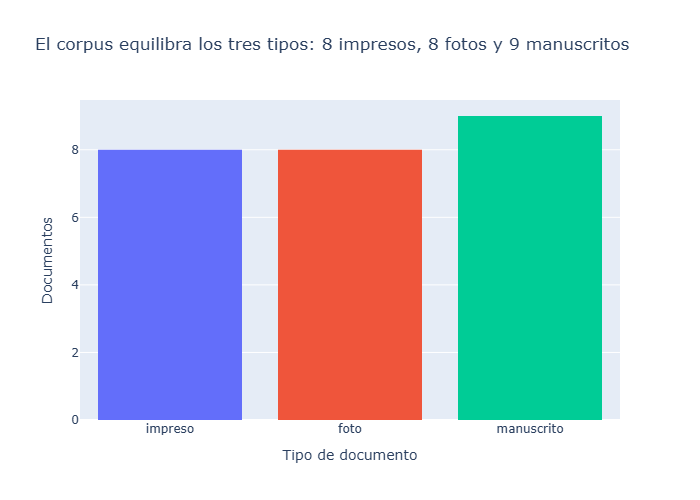

In [10]:
docs["caracteres_ocr"] = docs["texto_ocr"].str.len()
audio["palabras_asr"] = audio["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()

orden = ["impreso", "foto", "manuscrito"]
fig = px.histogram(docs, x="tipo", color="tipo", category_orders={"tipo": orden},
                   title="El corpus equilibra los tres tipos: 8 impresos, 8 fotos y 9 manuscritos",
                   labels={"tipo": "Tipo de documento", "count": "Documentos"})
fig.update_layout(showlegend=False, yaxis_title="Documentos")
fig.show()

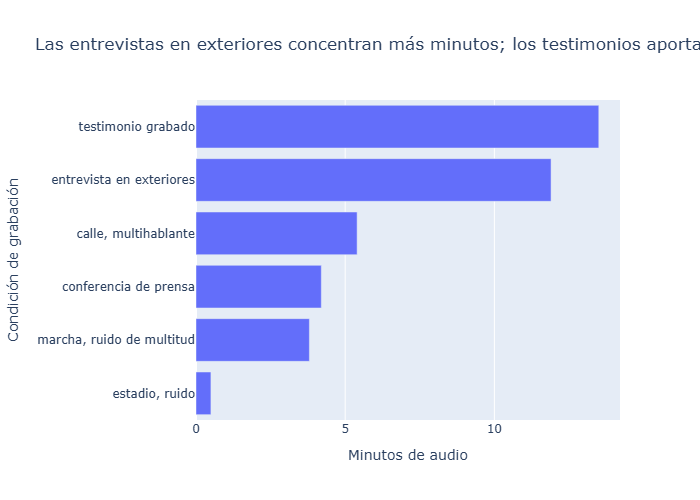

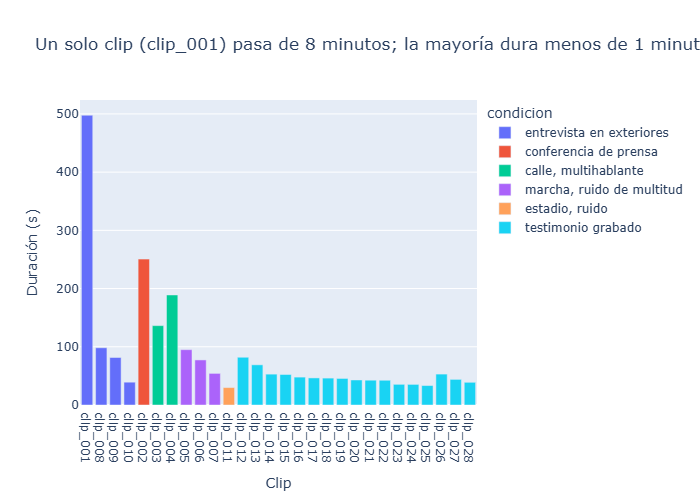

In [11]:
por_cond = audio.groupby("condicion", as_index=False)["duracion_seg"].sum()
por_cond["minutos"] = (por_cond["duracion_seg"] / 60).round(1)
fig = px.bar(por_cond.sort_values("minutos"), x="minutos", y="condicion", orientation="h",
             title="Las entrevistas en exteriores concentran más minutos; los testimonios aportan muchos clips cortos",
             labels={"minutos": "Minutos de audio", "condicion": "Condición de grabación"})
fig.show()
fig = px.bar(audio, x="id", y="duracion_seg", color="condicion",
             title="Un solo clip (clip_001) pasa de 8 minutos; la mayoría dura menos de 1 minuto y medio",
             labels={"duracion_seg": "Duración (s)", "id": "Clip"})
fig.show()

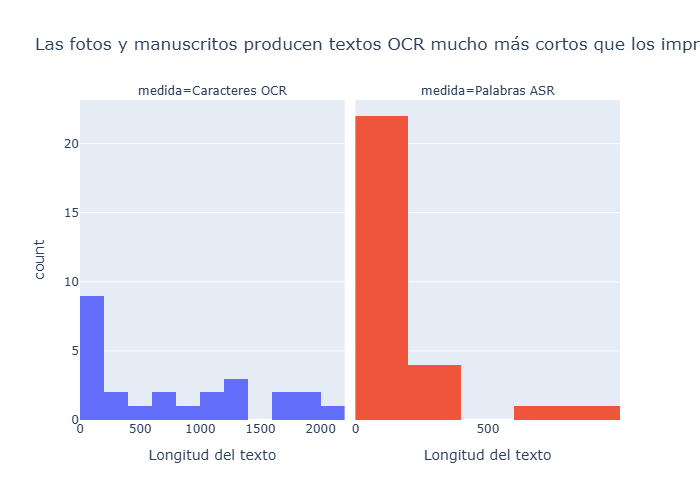

,count,mean,std,min,25%,50%,75%,max
tipo,,,,,,,,
foto,8.0,459.0,701.0,53.0,113.0,166.0,384.0,2131.0
impreso,8.0,1273.0,446.0,626.0,974.0,1250.0,1624.0,1942.0
manuscrito,9.0,586.0,667.0,42.0,78.0,191.0,1187.0,1829.0


In [12]:
largos = pd.concat([
    docs[["id", "tipo", "caracteres_ocr"]].rename(columns={"tipo": "grupo", "caracteres_ocr": "longitud"}).assign(medida="Caracteres OCR"),
    audio[["id", "condicion", "palabras_asr"]].rename(columns={"condicion": "grupo", "palabras_asr": "longitud"}).assign(medida="Palabras ASR"),
])
fig = px.histogram(largos, x="longitud", facet_col="medida", color="medida", nbins=15,
                   title="Las fotos y manuscritos producen textos OCR mucho más cortos que los impresos; las transcripciones son más parejas",
                   labels={"longitud": "Longitud del texto"})
fig.update_xaxes(matches=None)
fig.update_layout(showlegend=False)
fig.show()
docs.groupby("tipo")["caracteres_ocr"].describe().round(0)

## 7. Validación: extremos de longitud

In [13]:
cols = ["id", "tipo", "caracteres_ocr", "texto_ocr"]
print("Documentos con OCR más largo"); display(docs.nlargest(3, "caracteres_ocr")[cols])
print("Documentos con OCR más corto"); display(docs.nsmallest(3, "caracteres_ocr")[cols])
cols = ["id", "condicion", "duracion_seg", "palabras_asr"]
print("Clips más largos"); display(audio.nlargest(3, "duracion_seg")[cols])
print("Clips más cortos"); display(audio.nsmallest(3, "duracion_seg")[cols])

Documentos con OCR más largo


,id,tipo,caracteres_ocr,texto_ocr
14,doc_015,foto,2131,"nás iempo S inicio 0 repág * EL DECAMERON la había olvidado, y luego lo levantó y lo a..."
0,doc_001,impreso,1942,(5) lo dice el mismo: (14) si esa sabiduria no era mas que redundancia de los inefable...
22,doc_023,manuscrito,1829,"reses, ypodran estor mimos hacer una mutacion repentina,yental 2 caso lalicenadebia er..."


Documentos con OCR más corto


,id,tipo,caracteres_ocr,texto_ocr
17,doc_018,manuscrito,42,Hosta el ate 8 necesita de Ds para neparlo
20,doc_021,manuscrito,44,"Selices Yas myeres m 0 son los mos hermoses"""
9,doc_010,foto,53,se no cazado si he una ohe alcanzad una estre rella 7


Clips más largos


,id,condicion,duracion_seg,palabras_asr
0,clip_001,entrevista en exteriores,497.7,969
1,clip_002,conferencia de prensa,250.6,639
3,clip_004,"calle, multihablante",189.0,366


Clips más cortos


,id,condicion,duracion_seg,palabras_asr
10,clip_011,"estadio, ruido",29.9,58
24,clip_025,testimonio grabado,33.4,117
23,clip_024,testimonio grabado,35.4,111


Los extremos coinciden con los histogramas: los OCR más largos son páginas impresas densas, y los más cortos son fotos de carteles o manuscritos con pocas líneas (o con letra que el OCR casi no reconoce). En audio, `clip_001` (8 min) es el valor atípico; los más cortos son testimonios de unos 30 s.

## 8. Exportación

In [14]:
Path("datos").mkdir(exist_ok=True)
documentos = docs[["id", "archivo", "tipo", "licencia", "texto_ocr", "modelo_ocr"]].rename(columns={"licencia": "fuente"})
documentos["fuente"] = docs["fuente_url"].where(docs["fuente_url"] != "Captura propia", "Captura propia") + " (" + docs["licencia"] + ")"
documentos["texto_referencia"] = ""
documentos.to_csv("datos/documentos.csv", index=False)

transcripciones = pd.DataFrame({
    "id": audio["id"], "archivo_audio": "datos/raw/audio/" + audio["id"] + ".wav",
    "duracion_seg": audio["duracion_seg"],
    "idioma": "es (español peruano, según la descripción de cada archivo en Wikimedia Commons)",
    "texto_asr": audio["texto_asr"], "modelo_asr": audio["modelo_asr"], "n_hablantes": audio["n_hablantes"],
    "texto_referencia": "",
})
transcripciones.to_csv("datos/transcripciones.csv", index=False)

fuentes = pd.concat([
    docs[["id", "modalidad", "fuente_url", "licencia", "acceso", "descripcion"]],
    fuentes_audio.assign(descripcion=fuentes_audio["condicion"] + " — autor/a de la grabación: " + fuentes_audio["autor"])[["id", "modalidad", "fuente_url", "licencia", "acceso", "descripcion"]],
], ignore_index=True)
fuentes.to_csv("datos/fuentes.csv", index=False)

for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv", df.shape)

datos/documentos.csv (25, 7)
datos/transcripciones.csv (28, 8)
datos/fuentes.csv (53, 6)


In [15]:
documentos.head()

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,https://archive.org/details/cartapastoralque00orih/page/n10 (Dominio público (obra ant...,(5) lo dice el mismo: (14) si esa sabiduria no era mas que redundancia de los inefable...,"PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, lang=es, sin orientación ni unwarpin...",
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,https://archive.org/details/constitucionpoli00peru/page/n8 (Dominio público (obra ante...,5 SLITRA OAG- CAPITULOIII. st eb obio PamDbe w8no RELIJION. t.TA omls Art. 8. La Reli...,"PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, lang=es, sin orientación ni unwarpin...",
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,https://archive.org/details/constitucionpoli00peru/page/n14 (Dominio público (obra ant...,m ART. 35. Los colejios electorales de par- roquia remitirán cerradas y selladas á la ...,"PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, lang=es, sin orientación ni unwarpin...",
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,https://archive.org/details/basesdelaconstit00peru/page/n3 (Dominio público (obra ante...,"V. Su Religion es la Católica, Apostólica, Romana, con exclusion del ejercicio de cual...","PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, lang=es, sin orientación ni unwarpin...",
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,https://archive.org/details/mercurioperuanod00cale/page/n12 (Dominio público (obra ant...,Fol. Núm. 583. hiz ses sb sionsrib ab sibemt ecugol 12 0 bbbelb MERCURIO PERUANO ofbe ...,"PaddleOCR 3.7.0 (PP-OCRv5 mobile det + latin rec, lang=es, sin orientación ni unwarpin...",


In [16]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,497.7,"es (español peruano, según la descripción de cada archivo en Wikimedia Commons)","Bien, estamos en Plaza San Martín. Antes que nada, ¿me podría decir su nombre, por fav...",faster-whisper (Whisper turbo en CTranslate2) (mobiuslabsgmbh/faster-whisper-large-v3-...,1,
1,clip_002,datos/raw/audio/clip_002.wav,250.6,"es (español peruano, según la descripción de cada archivo en Wikimedia Commons)",bueno ahora estamos en los san martín entre fiestas patrias de julio entonces primero ...,faster-whisper (Whisper turbo en CTranslate2) (mobiuslabsgmbh/faster-whisper-large-v3-...,1,
2,clip_003,datos/raw/audio/clip_003.wav,136.3,"es (español peruano, según la descripción de cada archivo en Wikimedia Commons)","[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...",faster-whisper (Whisper turbo en CTranslate2) (mobiuslabsgmbh/faster-whisper-large-v3-...,2,
3,clip_004,datos/raw/audio/clip_004.wav,189.0,"es (español peruano, según la descripción de cada archivo en Wikimedia Commons)","[HABLANTE_1] Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa ...",faster-whisper (Whisper turbo en CTranslate2) (mobiuslabsgmbh/faster-whisper-large-v3-...,3,
4,clip_005,datos/raw/audio/clip_005.wav,95.0,"es (español peruano, según la descripción de cada archivo en Wikimedia Commons)","Ahora, mi nombre [PERSONA_06] voy a presentar a hacerle unas preguntas al señor para e...",faster-whisper (Whisper turbo en CTranslate2) (mobiuslabsgmbh/faster-whisper-large-v3-...,1,


In [17]:
fuentes.head()

,id,modalidad,fuente_url,licencia,acceso,descripcion
0,doc_001,documento,https://archive.org/details/cartapastoralque00orih/page/n10,Dominio público (obra anterior a 1900),Descarga directa: https://archive.org/download/cartapastoralque00orih/page/n10_w1500.j...,"Carta pastoral del obispo José Calixto de Orihuela, Lima 1820"
1,doc_002,documento,https://archive.org/details/constitucionpoli00peru/page/n8,Dominio público (obra anterior a 1900),Descarga directa: https://archive.org/download/constitucionpoli00peru/page/n8_w1500.jp...,"Constitución Política de la República Peruana, 1823 (cap. III-IV)"
2,doc_003,documento,https://archive.org/details/constitucionpoli00peru/page/n14,Dominio público (obra anterior a 1900),Descarga directa: https://archive.org/download/constitucionpoli00peru/page/n14_w1500.j...,"Constitución Política de la República Peruana, 1823 (colegios electorales)"
3,doc_004,documento,https://archive.org/details/basesdelaconstit00peru/page/n3,Dominio público (obra anterior a 1900),Descarga directa: https://archive.org/download/basesdelaconstit00peru/page/n3_w1500.jp...,"Bases de la Constitución Política de la República Peruana, 1822"
4,doc_005,documento,https://archive.org/details/mercurioperuanod00cale/page/n12,Dominio público (obra anterior a 1900),Descarga directa: https://archive.org/download/mercurioperuanod00cale/page/n12_w1500.j...,"Mercurio Peruano n.º 383, Lima 1791"
